# Model selection across 100 tuning and training seeds

Compare the six models reported in the paper: logistic regression, random forest, CatBoost, CatBoost + SMOTE, CatBoost ranker and CatBoost + ES. Each model gets seeds **1–100**, with a fresh **25-trial Optuna TPE search** for each seed: **600 studies / 15,000 trials**, followed by 600 final fits.

The 290 historical training events are split chronologically into **232 inner-training / 58 inner-tuning** events. Preprocessing priors, SMOTE and fitting use only the training side of each phase. Hyperparameters and CatBoost stopping iterations are chosen on inner tuning. The chosen configuration is then fitted on all 290 training events and scored on the fixed **103-event validation sample**. The 80 test events are never loaded here.

Choose the model family with the largest mean validation Top@k%AUC over the 100 seeds; ties use lower standard deviation, then model key. Seed 42 is specified in advance for the selected family's final checkpoint, avoiding selection of a lucky individual seed. These distributions measure tuning/training randomness on fixed data; they are not confidence intervals over new pump events.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import Image, display
from pumps_and_dumps.core.paths import get_root_dir

ROOT = get_root_dir()
sys.path.insert(0, str(ROOT))
from research_snapshots.seed_sweep import DEFAULT_OUTPUT, prepare, run_all, summarize, available_cpus

OUTPUT = DEFAULT_OUTPUT
SEEDS = list(range(1, 101))
TRIALS_PER_SEED = 25
WORKERS = available_cpus()  # All available CPUs; one thread per independent study.


## Run or resume

Run the following command from the repository root, or enable the cell below:

```bash
MPLBACKEND=Agg .venv/bin/python -m research_snapshots.seed_sweep run --workers all --start-seed 1
```

Studies are stored under `studies/<model>/seed_<seed>/studies.db` inside the experiment directory. Completed studies are reused after checksum verification. Interrupted studies are archived and restarted from their original seed. The existing root `studies.db` and paper results are preserved.

In [2]:
RUN_SEARCHES = False  # Set True to launch the complete experiment from this notebook.
if RUN_SEARCHES:
    prepare(OUTPUT, SEEDS, TRIALS_PER_SEED, WORKERS)
    run_all(OUTPUT, WORKERS)
else:
    print("Run the command above, or inspect the active experiment below.")


Run the command above, or inspect the active experiment below.


In [3]:
if (OUTPUT / "config.json").exists():
    status = summarize(OUTPUT, WORKERS)
    display(status)
    if (OUTPUT / "validation_results.csv").exists():
        completed = pd.read_csv(OUTPUT / "validation_results.csv")
        display(completed.groupby("label").agg(completed_seeds=("seed", "count")))
else:
    print("The experiment has not started.")


{'completed_studies': 600,
 'expected_studies': 600,
 'workers': 32,
 'estimated_serial_hours': 253.88251353930772,
 'estimated_parallel_hours': 7.933828548103366,
 'estimated_remaining_hours': np.float64(0.0),
 'selected_model': 'catboost',
 'status': 'complete'}

,completed_seeds
label,
CatBoost,100
CatBoost + ES,100
CatBoost + SMOTE,100
CatBoost ranker,100
Logistic regression,100
Random forest,100


## Compare complete distributions

Report the mean, standard deviation, median, interquartile range and central 95% seed range for each model. `paired_seed_differences.csv` compares models using the same seed indices, with bootstrap intervals for the mean difference across seeds. These intervals condition on the fixed event sample and do not establish out-of-sample superiority. The final selection is withheld until all 600 studies finish.

,count,mean,std,min,2.5%,25%,50%,75%,97.5%,max,win_fraction
model,,,,,,,,,,,
catboost,100.0,0.615045,0.025148,0.503641,0.559921,0.601578,0.619782,0.631462,0.648192,0.649515,0.52
logistic,100.0,0.610154,0.003640,0.592961,0.599563,0.609345,0.611044,0.612257,0.613471,0.614684,0.25
catboost_es,100.0,0.590274,0.041845,0.331432,0.499114,0.573149,0.593689,0.620601,0.639396,0.643325,0.23
forest,100.0,0.563511,0.015440,0.526214,0.535112,0.552063,0.565109,0.574181,0.592139,0.597694,0.00
ranker,100.0,0.518883,0.018295,0.470146,0.477479,0.508799,0.519842,0.529794,0.551596,0.565777,0.00
smote,100.0,0.484913,0.018230,0.380218,0.453880,0.475303,0.486711,0.495540,0.513362,0.520146,0.00


,model_a,model_b,mean_difference,ci_lower,ci_upper,scope
0,logistic,forest,0.046643,0.043413,0.049800,Paired seed variation conditional on these fix...
1,logistic,catboost,-0.004891,-0.009609,0.000284,Paired seed variation conditional on these fix...
2,logistic,smote,0.125242,0.121744,0.129084,Paired seed variation conditional on these fix...
3,logistic,ranker,0.091271,0.087695,0.094817,Paired seed variation conditional on these fix...
4,logistic,catboost_es,0.019880,0.012506,0.028342,Paired seed variation conditional on these fix...
5,forest,catboost,-0.051534,-0.057174,-0.045596,Paired seed variation conditional on these fix...
6,forest,smote,0.078598,0.073582,0.083802,Paired seed variation conditional on these fix...
7,forest,ranker,0.044627,0.040027,0.049282,Paired seed variation conditional on these fix...
8,forest,catboost_es,-0.026763,-0.034924,-0.017313,Paired seed variation conditional on these fix...
9,catboost,smote,0.130132,0.123970,0.136056,Paired seed variation conditional on these fix...


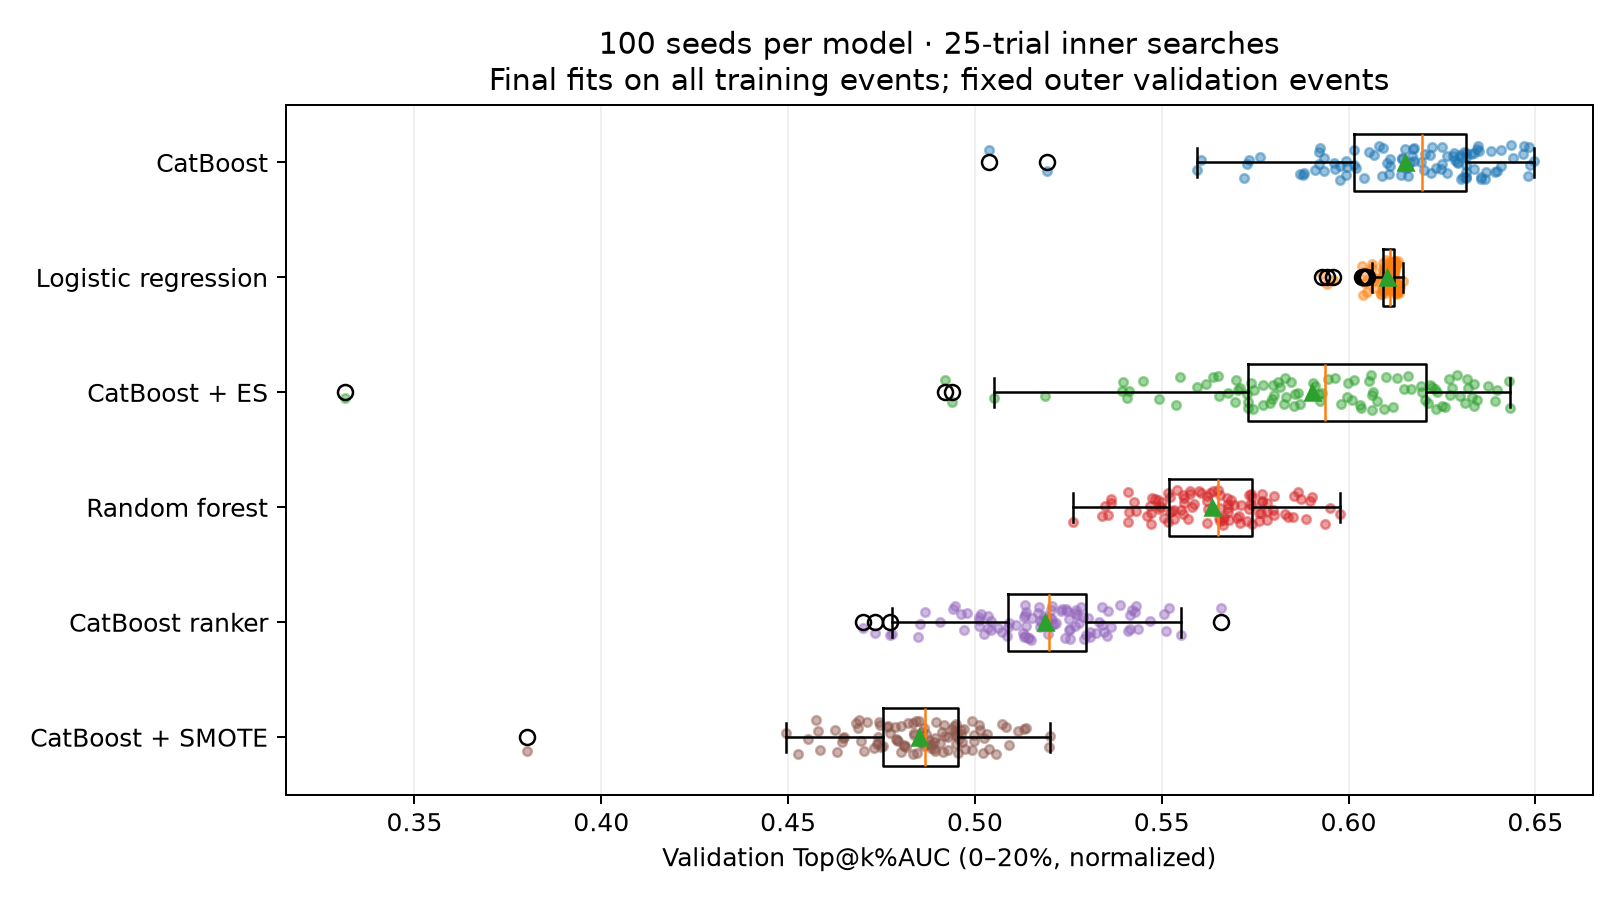

Selected model: CatBoost; mean validation AUC: 0.615045
Final model checkpoint: /home/borokoko/dev/pumps_and_dumps/notebooks/analysis_outputs/validation_seed_sweep_100x25/selected_model.pickle (preselected seed 42)


In [4]:
if (OUTPUT / "selection.json").exists():
    display(pd.read_csv(OUTPUT / "model_distributions.csv", index_col=0))
    display(pd.read_csv(OUTPUT / "paired_seed_differences.csv"))
    display(Image(filename=str(OUTPUT / "validation_seed_distributions.png")))
    selection = json.loads((OUTPUT / "selection.json").read_text())
    print(f"Selected model: {selection['label']}; mean validation AUC: {selection['mean_validation_auc']:.6f}")
    print(f"Final model checkpoint: {OUTPUT / 'selected_model.pickle'} (preselected seed {selection['final_seed']})")
else:
    print("Selection is pending completion of all 100 seeds for all six models.")
